Cell 1 : Imports and Reproducibility

In [4]:
# ============================================================
# Cell 1 — Imports and Reproducibility
# ============================================================

import os
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split

print("PyTorch version:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Fixed seeds required by the assignment
DATA_SEED = 42
RUN_SEEDS = [42, 123, 2026]

# Training settings
BATCH_SIZE = 32
MAX_EPOCHS = 60
LEARNING_RATE = 0.001

# CIFAR-10 normalization
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Reproducibility
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(DATA_SEED)

print("Seeds:", RUN_SEEDS)
print("Max epochs:", MAX_EPOCHS)
print("Batch size:", BATCH_SIZE)

PyTorch version: 2.11.0+cu130
Device: cuda
Seeds: [42, 123, 2026]
Max epochs: 60
Batch size: 32


Cell 2 : Load CIFAR-10

In [3]:
# ============================================================
# Cell 2 — Load CIFAR-10
# ============================================================

DATA_DIR = "./data"

# Raw CIFAR-10 datasets
cifar_train_raw = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True
)

cifar_test_raw = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True
)

print("Full training set:", len(cifar_train_raw))
print("Full test set:", len(cifar_test_raw))

print("Classes:")
print(cifar_train_raw.classes)

Full training set: 50000
Full test set: 10000
Classes:
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Cell 3 : Create train_small = 500 Images

In [5]:
# ============================================================
# Cell 3 — Create train_small
# 500 images total = 50 images per class
# ============================================================

targets = np.array(cifar_train_raw.targets)

train_small_indices = []

for class_id in range(10):

    class_indices = np.where(targets == class_id)[0]

    # Fixed random selection
    rng = np.random.default_rng(DATA_SEED)

    selected = rng.choice(
        class_indices,
        size=50,
        replace=False
    )

    train_small_indices.extend(selected.tolist())


train_small_indices = np.array(train_small_indices)

print("Total train_small images:", len(train_small_indices))

# Verify 50 images per class
print("\nImages per class:")

for class_id, class_name in enumerate(cifar_train_raw.classes):

    count = np.sum(targets[train_small_indices] == class_id)

    print(f"{class_name:10s}: {count}")

Total train_small images: 500

Images per class:
airplane  : 50
automobile: 50
bird      : 50
cat       : 50
deer      : 50
dog       : 50
frog      : 50
horse     : 50
ship      : 50
truck     : 50


Cell 4 : Split 400 Training / 100 Validation

In [6]:
# ============================================================
# Cell 4 — Stratified 400/100 Train-Validation Split
# ============================================================

small_targets = targets[train_small_indices]

train_indices, val_indices = train_test_split(
    train_small_indices,
    test_size=100,
    random_state=DATA_SEED,
    stratify=small_targets
)

print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))

# Verify class distribution
print("\nTraining distribution:")

for class_id, class_name in enumerate(cifar_train_raw.classes):

    count = np.sum(targets[train_indices] == class_id)

    print(f"{class_name:10s}: {count}")


print("\nValidation distribution:")

for class_id, class_name in enumerate(cifar_train_raw.classes):

    count = np.sum(targets[val_indices] == class_id)

    print(f"{class_name:10s}: {count}")

Training images: 400
Validation images: 100

Training distribution:
airplane  : 40
automobile: 40
bird      : 40
cat       : 40
deer      : 40
dog       : 40
frog      : 40
horse     : 40
ship      : 40
truck     : 40

Validation distribution:
airplane  : 10
automobile: 10
bird      : 10
cat       : 10
deer      : 10
dog       : 10
frog      : 10
horse     : 10
ship      : 10
truck     : 10


Cell 5 : Baseline Transforms

In [7]:
# ============================================================
# Cell 5 — Baseline Transforms
# ============================================================

baseline_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        CIFAR10_MEAN,
        CIFAR10_STD
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        CIFAR10_MEAN,
        CIFAR10_STD
    )
])

print("Baseline training transform:")
print(baseline_transform)

print("\nEvaluation transform:")
print(eval_transform)

Baseline training transform:
Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Evaluation transform:
Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)


Cell 6 : Create Datasets and DataLoaders

In [8]:
# ============================================================
# Cell 6 — Datasets and DataLoaders
# ============================================================

# Training dataset
baseline_train_dataset = Subset(
    datasets.CIFAR10(
        root=DATA_DIR,
        train=True,
        download=False,
        transform=baseline_transform
    ),
    train_indices
)

# Validation dataset
baseline_val_dataset = Subset(
    datasets.CIFAR10(
        root=DATA_DIR,
        train=True,
        download=False,
        transform=eval_transform
    ),
    val_indices
)

# Clean test dataset
clean_test_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=False,
    transform=eval_transform
)


def make_loader(dataset, shuffle=False, seed=42):

    generator = torch.Generator()

    generator.manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=2,
        pin_memory=torch.cuda.is_available(),
        generator=generator
    )


print("Training samples:", len(baseline_train_dataset))
print("Validation samples:", len(baseline_val_dataset))
print("Clean test samples:", len(clean_test_dataset))

Training samples: 400
Validation samples: 100
Clean test samples: 10000



Cell 7 : Inception-Style Module + Model

In [9]:
# ============================================================
# Cell 7 — Inception-Style CNN
# ============================================================

class InceptionBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        ch1x1,
        ch3_reduce,
        ch3,
        ch5_reduce,
        ch5,
        pool_proj
    ):

        super().__init__()

        # Branch 1: 1x1 convolution
        self.branch1 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                ch1x1,
                kernel_size=1
            ),
            nn.BatchNorm2d(ch1x1),
            nn.ReLU(inplace=True)
        )

        # Branch 2: 1x1 reduction -> 3x3
        self.branch3 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                ch3_reduce,
                kernel_size=1
            ),
            nn.BatchNorm2d(ch3_reduce),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                ch3_reduce,
                ch3,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(ch3),
            nn.ReLU(inplace=True)
        )

        # Branch 3: 1x1 reduction -> 5x5
        self.branch5 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                ch5_reduce,
                kernel_size=1
            ),
            nn.BatchNorm2d(ch5_reduce),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                ch5_reduce,
                ch5,
                kernel_size=5,
                padding=2
            ),
            nn.BatchNorm2d(ch5),
            nn.ReLU(inplace=True)
        )

        # Branch 4: pooling -> 1x1 projection
        self.branch_pool = nn.Sequential(
            nn.MaxPool2d(
                kernel_size=3,
                stride=1,
                padding=1
            ),

            nn.Conv2d(
                in_channels,
                pool_proj,
                kernel_size=1
            ),
            nn.BatchNorm2d(pool_proj),
            nn.ReLU(inplace=True)
        )


    def forward(self, x):

        branch1 = self.branch1(x)
        branch3 = self.branch3(x)
        branch5 = self.branch5(x)
        branch_pool = self.branch_pool(x)

        return torch.cat(
            [branch1, branch3, branch5, branch_pool],
            dim=1
        )


class BaselineCNN(nn.Module):

    def __init__(self, num_classes=10):

        super().__init__()

        # Initial convolution
        self.stem = nn.Sequential(

            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(2)
        )

        # Inception-style module
        self.inception1 = InceptionBlock(
            in_channels=32,

            ch1x1=16,

            ch3_reduce=16,
            ch3=24,

            ch5_reduce=8,
            ch5=16,

            pool_proj=8
        )

        # Output = 16 + 24 + 16 + 8 = 64
        self.pool1 = nn.MaxPool2d(2)

        # Second convolution block
        self.conv2 = nn.Sequential(

            nn.Conv2d(
                64,
                96,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(96),

            nn.ReLU(inplace=True),

            nn.MaxPool2d(2)
        )

        # Convert feature maps into 1x1
        self.global_pool = nn.AdaptiveAvgPool2d(
            (1, 1)
        )

        # Classifier
        self.classifier = nn.Sequential(

            nn.Linear(
                96,
                64
            ),

            nn.ReLU(inplace=True),

            nn.Dropout(0.5),

            nn.Linear(
                64,
                num_classes
            )
        )


    def forward(self, x):

        x = self.stem(x)

        x = self.inception1(x)

        x = self.pool1(x)

        x = self.conv2(x)

        x = self.global_pool(x)

        x = torch.flatten(
            x,
            1
        )

        x = self.classifier(x)

        return x

Cell 8 : Check Trainable Parameters

In [10]:
# ============================================================
# Cell 8 — Parameter Count Check
# ============================================================

model_check = BaselineCNN().to(DEVICE)

trainable_params = sum(
    p.numel()
    for p in model_check.parameters()
    if p.requires_grad
)

print(
    f"Trainable parameters: {trainable_params:,}"
)

print(
    f"Under 1,000,000 limit: "
    f"{trainable_params <= 1_000_000}"
)

Trainable parameters: 71,858
Under 1,000,000 limit: True


Cell 9 : Training Function

In [11]:
# ============================================================
# Cell 9 — Baseline Training Function
# ============================================================

def train_baseline(
    model,
    train_loader,
    val_loader,
    seed,
    max_epochs=60
):

    set_seed(seed)

    model = model.to(DEVICE)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_acc = -1.0
    best_epoch = 0
    best_state = None

    for epoch in range(max_epochs):

        # -------------------------
        # Training
        # -------------------------

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total

        # -------------------------
        # Validation
        # -------------------------

        model.eval()

        val_loss_total = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

                val_loss_total += (
                    loss.item() * images.size(0)
                )

                predictions = outputs.argmax(
                    dim=1
                )

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss = val_loss_total / val_total

        val_acc = (
            100.0 *
            val_correct /
            val_total
        )

        # Save history
        history["train_loss"].append(
            train_loss
        )

        history["train_acc"].append(
            train_acc
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_acc"].append(
            val_acc
        )

        # Keep best validation checkpoint
        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Seed {seed} | "
            f"Epoch {epoch + 1:02d}/{max_epochs} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}%"
        )

    # Restore best validation model
    model.load_state_dict(best_state)

    return (
        model,
        history,
        best_val_acc,
        best_epoch
    )

Cell 10 : Evaluation Function

In [12]:
# ============================================================
# Cell 10 — Evaluation Function
# ============================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    accuracy = (
        100.0 *
        correct /
        total
    )

    return accuracy

Cell 11 : Train Baseline with 3 Seeds

In [13]:
# ============================================================
# Cell 11 — Train Baseline for 3 Seeds
# ============================================================

baseline_models = {}
baseline_histories = {}
baseline_records = []

for seed in RUN_SEEDS:

    print("\n" + "=" * 70)
    print(f"TRAINING BASELINE — SEED {seed}")
    print("=" * 70)

    set_seed(seed)

    train_loader = make_loader(
        baseline_train_dataset,
        shuffle=True,
        seed=seed
    )

    val_loader = make_loader(
        baseline_val_dataset,
        shuffle=False,
        seed=seed
    )

    model = BaselineCNN().to(DEVICE)

    model, history, best_val_acc, best_epoch = train_baseline(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        seed=seed,
        max_epochs=MAX_EPOCHS
    )

    baseline_models[seed] = copy.deepcopy(model)
    baseline_histories[seed] = history

    # Training accuracy at the best epoch
    train_acc_at_best = history["train_acc"][best_epoch - 1]

    baseline_records.append({
        "Seed": seed,
        "Best Epoch": best_epoch,
        "Train Acc at Best": train_acc_at_best,
        "Best Val Acc": best_val_acc
    })

baseline_val_df = pd.DataFrame(
    baseline_records
)

display(baseline_val_df)


TRAINING BASELINE — SEED 42
Seed 42 | Epoch 01/60 | Train Acc: 13.75% | Val Acc: 20.00%
Seed 42 | Epoch 02/60 | Train Acc: 23.25% | Val Acc: 24.00%
Seed 42 | Epoch 03/60 | Train Acc: 26.50% | Val Acc: 29.00%
Seed 42 | Epoch 04/60 | Train Acc: 30.75% | Val Acc: 32.00%
Seed 42 | Epoch 05/60 | Train Acc: 28.75% | Val Acc: 32.00%
Seed 42 | Epoch 06/60 | Train Acc: 29.75% | Val Acc: 35.00%
Seed 42 | Epoch 07/60 | Train Acc: 38.75% | Val Acc: 39.00%
Seed 42 | Epoch 08/60 | Train Acc: 40.25% | Val Acc: 36.00%
Seed 42 | Epoch 09/60 | Train Acc: 40.75% | Val Acc: 40.00%
Seed 42 | Epoch 10/60 | Train Acc: 38.75% | Val Acc: 41.00%
Seed 42 | Epoch 11/60 | Train Acc: 45.00% | Val Acc: 39.00%
Seed 42 | Epoch 12/60 | Train Acc: 47.25% | Val Acc: 38.00%
Seed 42 | Epoch 13/60 | Train Acc: 44.50% | Val Acc: 38.00%
Seed 42 | Epoch 14/60 | Train Acc: 47.75% | Val Acc: 35.00%
Seed 42 | Epoch 15/60 | Train Acc: 47.25% | Val Acc: 39.00%
Seed 42 | Epoch 16/60 | Train Acc: 52.25% | Val Acc: 46.00%
Seed 42 | E

,Seed,Best Epoch,Train Acc at Best,Best Val Acc
0,42,33,79.00,49.0
1,123,46,89.50,49.0
2,2026,34,82.25,46.0


Cell 12 : Plot Learning Curves

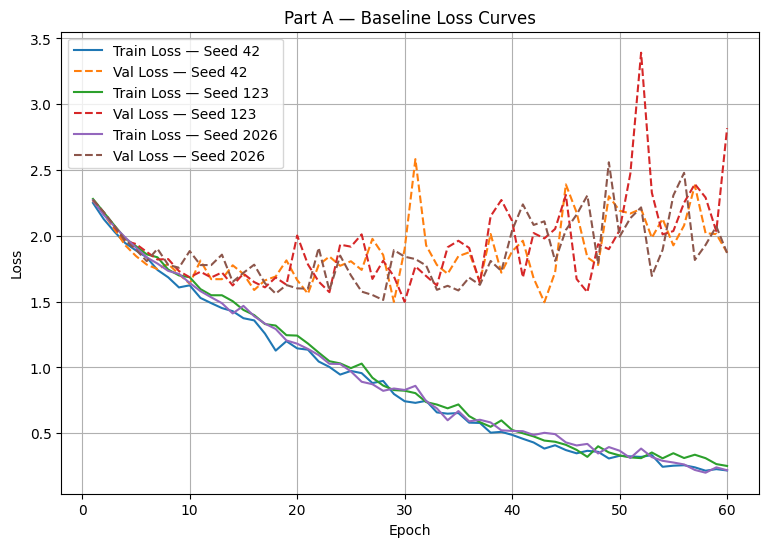

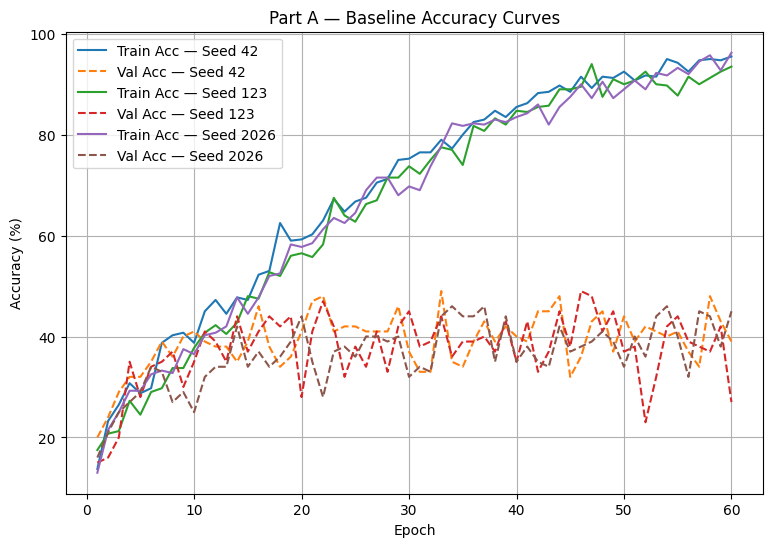

In [14]:
# ============================================================
# Cell 12 — Baseline Learning Curves
# ============================================================

# -------------------------
# Loss curves
# -------------------------

plt.figure(figsize=(9, 6))

for seed in RUN_SEEDS:

    history = baseline_histories[seed]

    epochs = range(
        1,
        len(history["train_loss"]) + 1
    )

    plt.plot(
        epochs,
        history["train_loss"],
        label=f"Train Loss — Seed {seed}"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        linestyle="--",
        label=f"Val Loss — Seed {seed}"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Part A — Baseline Loss Curves")
plt.legend()
plt.grid(True)
plt.show()


# -------------------------
# Accuracy curves
# -------------------------

plt.figure(figsize=(9, 6))

for seed in RUN_SEEDS:

    history = baseline_histories[seed]

    epochs = range(
        1,
        len(history["train_acc"]) + 1
    )

    plt.plot(
        epochs,
        history["train_acc"],
        label=f"Train Acc — Seed {seed}"
    )

    plt.plot(
        epochs,
        history["val_acc"],
        linestyle="--",
        label=f"Val Acc — Seed {seed}"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Part A — Baseline Accuracy Curves")
plt.legend()
plt.grid(True)
plt.show()

Cell 13 : Clean Test Evaluation

In [15]:
# ============================================================
# Cell 13 — Clean Test Evaluation
# ============================================================

clean_test_loader = make_loader(
    clean_test_dataset,
    shuffle=False,
    seed=DATA_SEED
)

clean_test_results = []

for seed in RUN_SEEDS:

    model = baseline_models[seed]

    clean_acc = evaluate_model(
        model,
        clean_test_loader
    )

    clean_test_results.append({
        "Seed": seed,
        "Clean Test Accuracy": clean_acc
    })

clean_test_df = pd.DataFrame(
    clean_test_results
)

display(clean_test_df)

print(
    "Clean Test Mean ± Std: "
    f"{clean_test_df['Clean Test Accuracy'].mean():.2f} ± "
    f"{clean_test_df['Clean Test Accuracy'].std(ddof=1):.2f}%"
)

,Seed,Clean Test Accuracy
0,42,37.60
1,123,41.67
2,2026,39.77


Clean Test Mean ± Std: 39.68 ± 2.04%


Cell 14 : Construct Shifted Test


In [16]:
# ============================================================
# Cell 14 — Shifted-Test Dataset
# ============================================================

SHIFTED_SEED = 123

class ShiftedTestDataset(torch.utils.data.Dataset):

    def __init__(
        self,
        base_dataset,
        seed=123,
        use_hidden_corruption=False
    ):

        self.base_dataset = base_dataset
        self.seed = seed
        self.use_hidden_corruption = use_hidden_corruption

        self.to_tensor = transforms.ToTensor()

        self.normalize = transforms.Normalize(
            CIFAR10_MEAN,
            CIFAR10_STD
        )

    def __len__(self):
        return len(self.base_dataset)

    def apply_hidden_corruption(self, image):

        return image

    def __getitem__(self, index):

        image, label = self.base_dataset[index]

        # Make transformation deterministic per image
        rng = random.Random(
            self.seed + index
        )

        # -----------------------------------------
        # 1. Random rotation: approximately ±25°
        # -----------------------------------------

        angle = rng.uniform(
            -25,
            25
        )

        image = transforms.functional.rotate(
            image,
            angle
        )

        # -----------------------------------------
        # 2. Brightness / contrast changes
        # -----------------------------------------

        brightness_factor = rng.uniform(
            0.7,
            1.3
        )

        contrast_factor = rng.uniform(
            0.7,
            1.3
        )

        image = transforms.functional.adjust_brightness(
            image,
            brightness_factor
        )

        image = transforms.functional.adjust_contrast(
            image,
            contrast_factor
        )

        # -----------------------------------------
        # 3. Rectangular occlusion ~25%
        # -----------------------------------------

        image_np = np.array(image).copy()

        height, width, _ = image_np.shape

        # Approx. 25% of image area
        occ_h = int(height * 0.5)
        occ_w = int(width * 0.5)

        max_top = height - occ_h
        max_left = width - occ_w

        top = rng.randint(
            0,
            max_top
        )

        left = rng.randint(
            0,
            max_left
        )

        image_np[
            top:top + occ_h,
            left:left + occ_w,
            :
        ] = 0

        image = transforms.ToPILImage()(
            image_np
        )

        # -----------------------------------------
        # 4. Hidden corruption placeholder
        # -----------------------------------------

        if self.use_hidden_corruption:

            image = self.apply_hidden_corruption(
                image
            )

        # -----------------------------------------
        # Convert + normalize
        # -----------------------------------------

        image = self.to_tensor(image)

        image = self.normalize(image)

        return image, label


shifted_test_dataset = ShiftedTestDataset(
    base_dataset=cifar_test_raw,
    seed=SHIFTED_SEED,
    use_hidden_corruption=False
)

shifted_test_loader = make_loader(
    shifted_test_dataset,
    shuffle=False,
    seed=SHIFTED_SEED
)

print(
    "Shifted test images:",
    len(shifted_test_dataset)
)

Shifted test images: 10000


Cell 15 : Shifted Test Evaluation

In [17]:
# ============================================================
# Cell 15 — Shifted Test Evaluation
# ============================================================

shifted_test_results = []

for seed in RUN_SEEDS:

    model = baseline_models[seed]

    shifted_acc = evaluate_model(
        model,
        shifted_test_loader
    )

    shifted_test_results.append({
        "Seed": seed,
        "Shifted Test Accuracy": shifted_acc
    })

shifted_test_df = pd.DataFrame(
    shifted_test_results
)

display(shifted_test_df)

print(
    "Shifted Test Mean ± Std: "
    f"{shifted_test_df['Shifted Test Accuracy'].mean():.2f} ± "
    f"{shifted_test_df['Shifted Test Accuracy'].std(ddof=1):.2f}%"
)

,Seed,Shifted Test Accuracy
0,42,23.82
1,123,20.73
2,2026,14.29


Shifted Test Mean ± Std: 19.61 ± 4.86%


Cell 16 : Complete Part A Results Table

In [18]:
# ============================================================
# Cell 16 — Part A Final Results
# ============================================================

part_a_results = baseline_val_df.merge(
    clean_test_df,
    on="Seed"
).merge(
    shifted_test_df,
    on="Seed"
)

display(part_a_results)

,Seed,Best Epoch,Train Acc at Best,Best Val Acc,Clean Test Accuracy,Shifted Test Accuracy
0,42,33,79.00,49.0,37.60,23.82
1,123,46,89.50,49.0,41.67,20.73
2,2026,34,82.25,46.0,39.77,14.29


In [19]:
# ============================================================
# Cell 16B — Part A Mean ± Std
# ============================================================

print("PART A — BASELINE RESULTS")
print("=" * 60)

for column in [
    "Train Acc at Best",
    "Best Val Acc",
    "Clean Test Accuracy",
    "Shifted Test Accuracy"
]:

    mean_value = part_a_results[column].mean()

    std_value = part_a_results[column].std(
        ddof=1
    )

    print(
        f"{column}: "
        f"{mean_value:.2f} ± {std_value:.2f}%"
    )

PART A — BASELINE RESULTS
Train Acc at Best: 83.58 ± 5.38%
Best Val Acc: 48.00 ± 1.73%
Clean Test Accuracy: 39.68 ± 2.04%
Shifted Test Accuracy: 19.61 ± 4.86%


Cell 17 : Part A Diagnosis

## Part A Baseline Diagnosis

The baseline is trained on only 400 images, so a large gap between training and validation/clean-test accuracy indicates **overfitting**.

The lower shifted-test accuracy compared with clean-test accuracy indicates **covariate/distribution shift**, because the shifted images contain transformations and corruptions that are not present in the clean training distribution.

Therefore, the baseline performance can be affected by **both overfitting and covariate shift**.

Part B :  Augmentation Strategy
Cell 18 : Part B Introduction

# Part B : Design Your Augmentation Strategy

The baseline model in Part A was trained without augmentation.

In Part B, i introduce training-time augmentation to improve robustness against the shifts present in the shifted test set.

The augmentation strategy is designed to target:
- Geometric changes
- Brightness and contrast changes
- Blur and noise
- Partial occlusion

All augmentations are applied on-the-fly during training only.

Cell 19 : Create Gaussian Noise Transform

In [20]:
# ============================================================
# Cell 19 — Gaussian Noise Transform
# ============================================================

class AddGaussianNoise:

    def __init__(self, std=0.05, p=0.5):
        self.std = std
        self.p = p

    def __call__(self, tensor):

        if torch.rand(1).item() < self.p:

            noise = torch.randn_like(tensor) * self.std

            tensor = tensor + noise

            tensor = torch.clamp(
                tensor,
                0.0,
                1.0
            )

        return tensor

Cell 20 : Geometric Augmentation

In [21]:
# ============================================================
# Cell 20 — Geometric Augmentation
# ============================================================

geometric_transform = transforms.Compose([

    # Small translations / cropping
    transforms.RandomCrop(
        32,
        padding=4
    ),

    # Horizontal reflection
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    # Match the known shifted-test rotation range
    transforms.RandomRotation(
        degrees=25
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        CIFAR10_MEAN,
        CIFAR10_STD
    )
])

print("Geometric augmentation:")
print("- RandomCrop with padding")
print("- RandomHorizontalFlip")
print("- RandomRotation ±25°")

Geometric augmentation:
- RandomCrop with padding
- RandomHorizontalFlip
- RandomRotation ±25°


Cell 21 : Photometric Augmentation

In [22]:
# ============================================================
# Cell 21 — Photometric Augmentation
# ============================================================

photometric_transform = transforms.Compose([

    # Brightness / contrast / color changes
    transforms.ColorJitter(
        brightness=0.30,
        contrast=0.30,
        saturation=0.20
    ),

    # Blur
    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3,
                sigma=(0.1, 1.0)
            )
        ],
        p=0.5
    ),

    transforms.ToTensor(),

    # Noise
    AddGaussianNoise(
        std=0.05,
        p=0.5
    ),

    transforms.Normalize(
        CIFAR10_MEAN,
        CIFAR10_STD
    )
])

print("Photometric augmentation:")
print("- ColorJitter")
print("- GaussianBlur")
print("- GaussianNoise")

Photometric augmentation:
- ColorJitter
- GaussianBlur
- GaussianNoise


Cell 22 : Geometric + Photometri

In [23]:
# ============================================================
# Cell 22 — Geometric + Photometric Augmentation
# ============================================================

geometric_photometric_transform = transforms.Compose([

    # -------------------------
    # Geometric
    # -------------------------

    transforms.RandomCrop(
        32,
        padding=4
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=25
    ),

    # -------------------------
    # Photometric
    # -------------------------

    transforms.ColorJitter(
        brightness=0.30,
        contrast=0.30,
        saturation=0.20
    ),

    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3,
                sigma=(0.1, 1.0)
            )
        ],
        p=0.5
    ),

    transforms.ToTensor(),

    AddGaussianNoise(
        std=0.05,
        p=0.5
    ),

    transforms.Normalize(
        CIFAR10_MEAN,
        CIFAR10_STD
    )
])

print("Combined augmentation:")
print("Geometric + Photometric")

Combined augmentation:
Geometric + Photometric


Cell 23 : Add Random Erasing

In [24]:
# ============================================================
# Cell 23 — Full Augmentation + Random Erasing
# ============================================================

full_augmentation_transform = transforms.Compose([

    # -------------------------
    # Geometric
    # -------------------------

    transforms.RandomCrop(
        32,
        padding=4
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=25
    ),

    # -------------------------
    # Photometric
    # -------------------------

    transforms.ColorJitter(
        brightness=0.30,
        contrast=0.30,
        saturation=0.20
    ),

    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3,
                sigma=(0.1, 1.0)
            )
        ],
        p=0.5
    ),

    transforms.ToTensor(),

    AddGaussianNoise(
        std=0.05,
        p=0.5
    ),

    transforms.Normalize(
        CIFAR10_MEAN,
        CIFAR10_STD
    ),

    # -------------------------
    # Occlusion robustness
    # -------------------------

    transforms.RandomErasing(
        p=0.5,
        scale=(0.02, 0.20),
        ratio=(0.5, 2.0),
        value=0
    )
])

print("Full augmentation:")
print("Geometric + Photometric + Random Erasing")

Full augmentation:
Geometric + Photometric + Random Erasing


Cell 24 : Create Augmented Training Datasets

In [25]:
# ============================================================
# Cell 24 — Augmented Training Datasets
# ============================================================

geometric_train_dataset = Subset(
    datasets.CIFAR10(
        root=DATA_DIR,
        train=True,
        download=False,
        transform=geometric_transform
    ),
    train_indices
)

photometric_train_dataset = Subset(
    datasets.CIFAR10(
        root=DATA_DIR,
        train=True,
        download=False,
        transform=photometric_transform
    ),
    train_indices
)

geometric_photometric_train_dataset = Subset(
    datasets.CIFAR10(
        root=DATA_DIR,
        train=True,
        download=False,
        transform=geometric_photometric_transform
    ),
    train_indices
)

full_augmentation_train_dataset = Subset(
    datasets.CIFAR10(
        root=DATA_DIR,
        train=True,
        download=False,
        transform=full_augmentation_transform
    ),
    train_indices
)

# Validation remains CLEAN — no augmentation
augmentation_val_dataset = Subset(
    datasets.CIFAR10(
        root=DATA_DIR,
        train=True,
        download=False,
        transform=eval_transform
    ),
    val_indices
)

print("Geometric training samples:",
      len(geometric_train_dataset))

print("Photometric training samples:",
      len(photometric_train_dataset))

print("Geometric + Photometric samples:",
      len(geometric_photometric_train_dataset))

print("Full augmentation samples:",
      len(full_augmentation_train_dataset))

print("Validation samples:",
      len(augmentation_val_dataset))

Geometric training samples: 400
Photometric training samples: 400
Geometric + Photometric samples: 400
Full augmentation samples: 400
Validation samples: 100


Cell 25 : Create DataLoaders

In [26]:
# ============================================================
# Cell 25 — Augmentation DataLoaders
# ============================================================

geometric_train_loader = make_loader(
    geometric_train_dataset,
    shuffle=True,
    seed=DATA_SEED
)

photometric_train_loader = make_loader(
    photometric_train_dataset,
    shuffle=True,
    seed=DATA_SEED
)

geometric_photometric_train_loader = make_loader(
    geometric_photometric_train_dataset,
    shuffle=True,
    seed=DATA_SEED
)

full_augmentation_train_loader = make_loader(
    full_augmentation_train_dataset,
    shuffle=True,
    seed=DATA_SEED
)

augmentation_val_loader = make_loader(
    augmentation_val_dataset,
    shuffle=False,
    seed=DATA_SEED
)

print("All augmentation DataLoaders created.")

All augmentation DataLoaders created.


Cell 26 : Verify Augmentation is On-the-Fly

In [27]:
# ============================================================
# Cell 26 — Verify On-the-Fly Augmentation
# ============================================================

print("Original training samples:", len(train_indices))

print(
    "Geometric dataset samples:",
    len(geometric_train_dataset)
)

print(
    "Photometric dataset samples:",
    len(photometric_train_dataset)
)

print(
    "Full augmentation samples:",
    len(full_augmentation_train_dataset)
)

print("\nNo pre-generated augmented copies are stored.")
print("Augmentations are generated dynamically during training.")

Original training samples: 400
Geometric dataset samples: 400
Photometric dataset samples: 400
Full augmentation samples: 400

No pre-generated augmented copies are stored.
Augmentations are generated dynamically during training.


Cell 27 : Visualize Augmentations

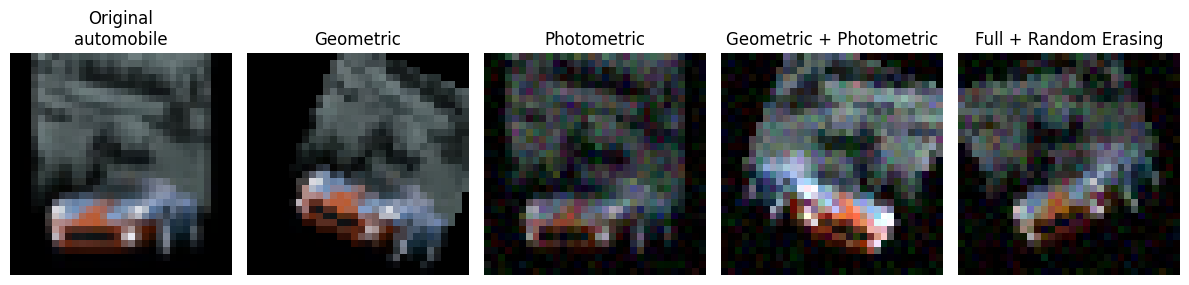

In [28]:
# ============================================================
# Cell 27 — Visualize Augmentations
# ============================================================

# Get one original CIFAR-10 image
original_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False
)

image, label = original_dataset[
    train_indices[0]
]

# Generate examples
augmented_images = [
    geometric_transform(image),
    photometric_transform(image),
    geometric_photometric_transform(image),
    full_augmentation_transform(image)
]

titles = [
    "Geometric",
    "Photometric",
    "Geometric + Photometric",
    "Full + Random Erasing"
]

# Function to unnormalize
def unnormalize_image(tensor):

    mean = torch.tensor(
        CIFAR10_MEAN
    ).view(3, 1, 1)

    std = torch.tensor(
        CIFAR10_STD
    ).view(3, 1, 1)

    tensor = tensor * std + mean

    return torch.clamp(
        tensor,
        0,
        1
    )


plt.figure(figsize=(12, 3))

# Original
plt.subplot(1, 5, 1)

plt.imshow(image)

plt.title(
    f"Original\n{cifar_train_raw.classes[label]}"
)

plt.axis("off")


# Augmented
for i, (img, title) in enumerate(
    zip(augmented_images, titles),
    start=2
):

    plt.subplot(
        1,
        5,
        i
    )

    img = unnormalize_image(img)

    plt.imshow(
        img.permute(1, 2, 0)
    )

    plt.title(title)

    plt.axis("off")


plt.tight_layout()
plt.show()

Cell 28 : Part B Required Question 1

## Part B : Question 1

### Would vertical flip help or hurt?

A vertical flip would generally **hurt** performance on CIFAR-10. Many classes, including animals and vehicles, have meaningful upright orientations. Vertical flipping can therefore create unrealistic training examples and make the small model learn unnecessary invariance.

For this reason, vertical flipping is **not included** in the final augmentation strategy.

Cell 29 : Part B Required Question 2

## Part B : Question 2

### What is the trade-off if rotation is increased to ±90° while the shifted test uses only ±25°?

Using ±90° rotation may make the model more invariant to extreme rotations, but most of these orientations are outside the target test distribution. With only 400 training images and a small model, excessive rotation can waste model capacity and introduce unrealistic examples.

Therefore, using **±25° rotation** is a better choice because it directly matches the known rotation range of the shifted test set.

Cell 30 — Part B Required Question 3

## Part B : Question 3

### Why can too much augmentation reduce accuracy on a small model?

Only 400 training images are available and the model has limited capacity. If augmentations are too strong, they can change or remove useful class-related visual features.

The model may then spend its limited capacity learning unrealistic variations instead of useful class features. This can cause underfitting and reduce validation and clean-test accuracy.

Therefore, augmentation should be strong enough to improve robustness but not so aggressive that it makes the training examples unrealistic.

Cell 31 : Part B Final Strategy

## Part B : Final Augmentation Strategy

The final strategy uses:

1. Random Crop with padding
2. Random Horizontal Flip
3. Random Rotation ±25°
4. Color Jitter
5. Gaussian Blur
6. Gaussian Noise
7. Random Erasing

These augmentations target the known geometric, photometric, blur/noise, and occlusion shifts in the shifted-test distribution.

Vertical Flip is excluded because it can create unrealistic upside-down objects.

All augmentations are applied **on-the-fly and only to the training data**.

Cell 32 : Part C Introduction
# Part C : Regularization & Training Improvements

To improve generalization on the small 400-image training set, i use:
- Batch Normalization
- Dropout
- Weight Decay
- Learning Rate Scheduling
- Early Stopping
- Label Smoothing

The validation set is used to select the best model/checkpoint.
The clean and shifted test sets are not used for tuning.

Cell 33 : Part C Training Function

In [29]:
def train_part_c(
    model,
    train_loader,
    val_loader,
    seed,
    max_epochs=60,
    lr=0.001,
    weight_decay=1e-4,
    label_smoothing=0.1,
    patience=10
):
    set_seed(seed)

    model = model.to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        label_smoothing=label_smoothing
    )

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=4
    )

    best_val_acc = 0.0
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0

    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "lr": []
    }

    for epoch in range(max_epochs):

        # -------------------------
        # Training
        # -------------------------
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total

        # -------------------------
        # Validation
        # -------------------------
        model.eval()

        val_loss_total = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_total += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)
                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_total / val_total
        val_acc = 100.0 * val_correct / val_total

        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(current_lr)

        # LR scheduling based ONLY on validation accuracy
        scheduler.step(val_acc)

        # -------------------------
        # Best checkpoint
        # -------------------------
        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        # -------------------------
        # Early stopping
        # -------------------------
        if epochs_without_improvement >= patience:
            print(
                f"Early stopping at epoch {epoch + 1}. "
                f"Best epoch: {best_epoch}"
            )
            break

        if (epoch + 1) % 5 == 0:
            print(
                f"Epoch [{epoch+1:02d}/{max_epochs}] | "
                f"Train Acc: {train_acc:.2f}% | "
                f"Val Acc: {val_acc:.2f}% | "
                f"LR: {current_lr:.6f}"
            )

    model.load_state_dict(best_state)

    return model, history, best_val_acc, best_epoch

Cell 34 : Create Part C Training Loader

In [30]:
part_c_train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    transform=full_augmentation_transform,
    download=False
)

part_c_train_dataset = Subset(
    part_c_train_dataset,
    train_indices
)

part_c_val_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    transform=eval_transform,
    download=False
)

part_c_val_dataset = Subset(
    part_c_val_dataset,
    val_indices
)

part_c_train_loader = make_loader(
    part_c_train_dataset,
    shuffle=True,
    seed=DATA_SEED
)

part_c_val_loader = make_loader(
    part_c_val_dataset,
    shuffle=False,
    seed=DATA_SEED
)

print("Part C training samples:", len(part_c_train_dataset))
print("Part C validation samples:", len(part_c_val_dataset))

Part C training samples: 400
Part C validation samples: 100


Cell 35 : Train Part C for 3 Seeds

In [31]:
part_c_results = {}

for seed in RUN_SEEDS:

    print("\n" + "=" * 60)
    print(f"PART C — SEED {seed}")
    print("=" * 60)

    set_seed(seed)

    model = BaselineCNN(num_classes=10)

    model, history, best_val_acc, best_epoch = train_part_c(
        model=model,
        train_loader=part_c_train_loader,
        val_loader=part_c_val_loader,
        seed=seed,
        max_epochs=MAX_EPOCHS,
        lr=LEARNING_RATE,
        weight_decay=1e-4,
        label_smoothing=0.1,
        patience=10
    )

    part_c_results[seed] = {
        "model": copy.deepcopy(model),
        "history": history,
        "best_val_acc": best_val_acc,
        "best_epoch": best_epoch
    }

    print(f"Best Epoch: {best_epoch}")
    print(f"Best Validation Accuracy: {best_val_acc:.2f}%")


PART C — SEED 42
Epoch [05/60] | Train Acc: 17.25% | Val Acc: 27.00% | LR: 0.001000
Epoch [10/60] | Train Acc: 19.75% | Val Acc: 21.00% | LR: 0.001000
Epoch [15/60] | Train Acc: 32.00% | Val Acc: 30.00% | LR: 0.001000
Epoch [20/60] | Train Acc: 31.75% | Val Acc: 33.00% | LR: 0.000500
Epoch [25/60] | Train Acc: 30.25% | Val Acc: 36.00% | LR: 0.000500
Epoch [30/60] | Train Acc: 31.50% | Val Acc: 35.00% | LR: 0.000250
Early stopping at epoch 33. Best epoch: 23
Best Epoch: 23
Best Validation Accuracy: 37.00%

PART C — SEED 123
Epoch [05/60] | Train Acc: 20.75% | Val Acc: 30.00% | LR: 0.001000
Epoch [10/60] | Train Acc: 21.25% | Val Acc: 36.00% | LR: 0.001000
Epoch [15/60] | Train Acc: 24.00% | Val Acc: 34.00% | LR: 0.001000
Epoch [20/60] | Train Acc: 27.75% | Val Acc: 37.00% | LR: 0.000500
Epoch [25/60] | Train Acc: 29.75% | Val Acc: 41.00% | LR: 0.000250
Early stopping at epoch 29. Best epoch: 19
Best Epoch: 19
Best Validation Accuracy: 43.00%

PART C — SEED 2026
Epoch [05/60] | Train Ac

Cell 36 : Plot Part C Learning Curves

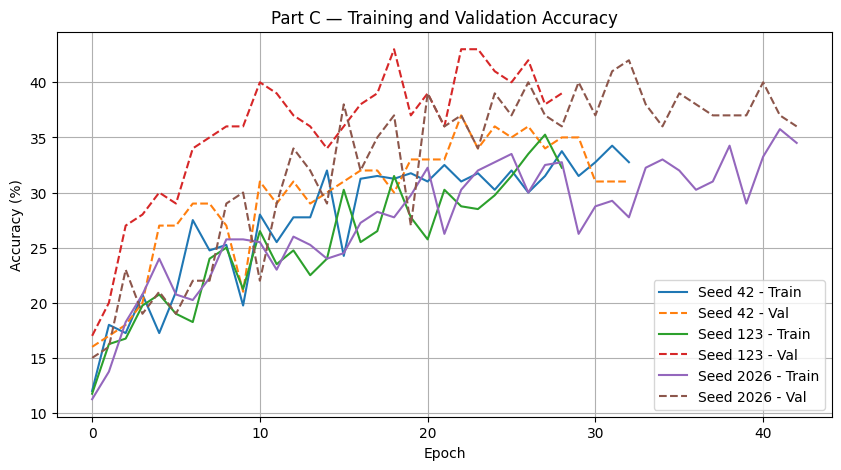

In [32]:
plt.figure(figsize=(10, 5))

for seed in RUN_SEEDS:
    history = part_c_results[seed]["history"]

    plt.plot(
        history["train_acc"],
        label=f"Seed {seed} - Train"
    )

    plt.plot(
        history["val_acc"],
        linestyle="--",
        label=f"Seed {seed} - Val"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Part C — Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Cell 37 : Learning Rate Curves

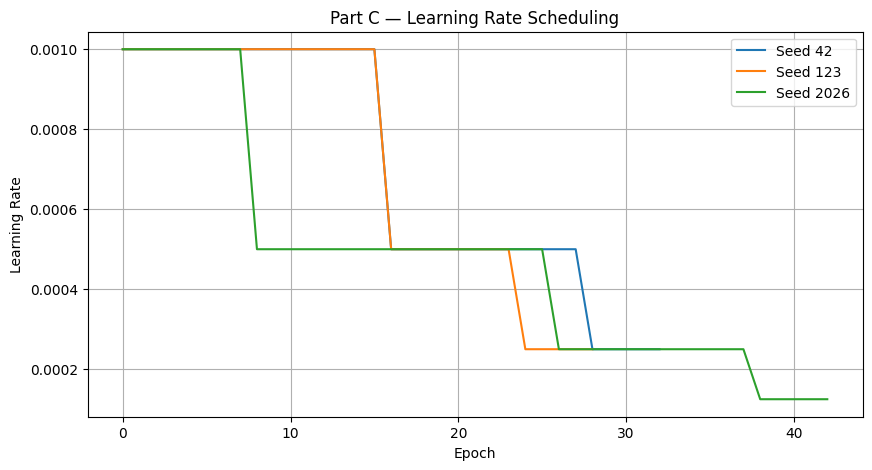

In [33]:
plt.figure(figsize=(10, 5))

for seed in RUN_SEEDS:
    history = part_c_results[seed]["history"]

    plt.plot(
        history["lr"],
        label=f"Seed {seed}"
    )

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Part C — Learning Rate Scheduling")
plt.legend()
plt.grid(True)
plt.show()

Cell 38 : Part C Validation Summary

In [34]:
part_c_val_scores = [
    part_c_results[seed]["best_val_acc"]
    for seed in RUN_SEEDS
]

print("Part C Validation Accuracy:")
for seed in RUN_SEEDS:
    print(
        f"Seed {seed}: "
        f"{part_c_results[seed]['best_val_acc']:.2f}% "
        f"(Epoch {part_c_results[seed]['best_epoch']})"
    )

print(
    f"\nMean ± Std: "
    f"{np.mean(part_c_val_scores):.2f} ± "
    f"{np.std(part_c_val_scores):.2f}%"
)

Part C Validation Accuracy:
Seed 42: 37.00% (Epoch 23)
Seed 123: 43.00% (Epoch 19)
Seed 2026: 42.00% (Epoch 33)

Mean ± Std: 40.67 ± 2.62%


Cell 39 : Part C Justification

### Why these techniques are used

**Batch Normalization:**  
BatchNorm is already included after convolutional layers to stabilize training and improve optimization.

**Dropout:**  
Dropout is placed after the fully connected layer because the classifier contains dense connections and can easily overfit the very small training set. It is not placed aggressively in early convolutional layers because this may remove useful spatial features.

**Weight Decay:**  
A small weight decay of 1e-4 penalizes excessively large weights and helps reduce overfitting.

**Learning Rate Scheduling:**  
ReduceLROnPlateau lowers the learning rate when validation accuracy stops improving, allowing more stable convergence.

**Early Stopping:**  
Training stops when validation accuracy does not improve for several epochs. This prevents unnecessary training and overfitting.

**Label Smoothing:**  
A smoothing value of 0.1 prevents the model from becoming overly confident in its predictions and can improve generalization on unseen data.

Cell 40 : Part D Introduction

# Part D : Ablation Study

The purpose of this ablation study is to measure the contribution of
different augmentation and regularization strategies.

Each configuration is trained using:
- The same 400 training images
- The same 100 validation images
- The same model architecture
- Three different random seeds

The validation set is used for model/checkpoint selection.

The clean test set and shifted test set are evaluated only after training
and are not used for hyperparameter tuning.

Cell 41 : Mixup Function

In [35]:
def mixup_data(images, labels, alpha=0.4):
    if alpha <= 0:
        return images, labels, labels, 1.0

    lam = np.random.beta(alpha, alpha)

    batch_size = images.size(0)
    index = torch.randperm(batch_size, device=images.device)

    mixed_images = (
        lam * images +
        (1 - lam) * images[index]
    )

    labels_a = labels
    labels_b = labels[index]

    return mixed_images, labels_a, labels_b, lam

Cell 42 : Mixup Loss

In [36]:
def mixup_loss(criterion, predictions, labels_a, labels_b, lam):
    return (
        lam * criterion(predictions, labels_a)
        + (1 - lam) * criterion(predictions, labels_b)
    )

Cell 43 : Ablation Training Function

In [37]:
def train_ablation(
    model,
    train_loader,
    val_loader,
    seed,
    use_mixup=False,
    label_smoothing=0.0,
    max_epochs=60,
    lr=0.001,
    weight_decay=1e-4,
    patience=10
):

    set_seed(seed)

    model = model.to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        label_smoothing=label_smoothing
    )

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=4
    )

    best_val_acc = 0.0
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())

    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(max_epochs):

        # =========================
        # Training
        # =========================
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            if use_mixup:

                mixed_images, labels_a, labels_b, lam = mixup_data(
                    images,
                    labels,
                    alpha=0.4
                )

                outputs = model(mixed_images)

                loss = mixup_loss(
                    criterion,
                    outputs,
                    labels_a,
                    labels_b,
                    lam
                )

                # Approximate training accuracy using original labels
                predictions = outputs.argmax(dim=1)
                correct += (
                    predictions == labels
                ).sum().item()

            else:

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

                predictions = outputs.argmax(dim=1)

                correct += (
                    predictions == labels
                ).sum().item()

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total

        # =========================
        # Validation
        # =========================
        model.eval()

        val_loss_total = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = model(images)

                val_loss = criterion(
                    outputs,
                    labels
                )

                val_loss_total += (
                    val_loss.item() * images.size(0)
                )

                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss = val_loss_total / val_total
        val_acc = 100.0 * val_correct / val_total

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # Scheduler uses validation only
        scheduler.step(val_acc)

        # =========================
        # Best checkpoint
        # =========================
        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_state)

    return (
        model,
        history,
        best_val_acc,
        best_epoch
    )

Cell 44 : Create Ablation Training Datasets

In [38]:
ablation_transforms = {
    "No Augmentation": baseline_transform,

    "Geometric Only": geometric_transform,

    "Photometric Only": photometric_transform,

    "Geometric + Photometric": geometric_photometric_transform,

    "+ Random Erasing": full_augmentation_transform,

    "+ Mixup + Label Smoothing": full_augmentation_transform,

    "Final Model": full_augmentation_transform
}

Cell 45 : Create Validation Dataset

In [39]:
ablation_val_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    transform=eval_transform,
    download=False
)

ablation_val_dataset = Subset(
    ablation_val_dataset,
    val_indices
)

ablation_val_loader = make_loader(
    ablation_val_dataset,
    shuffle=False,
    seed=DATA_SEED
)

print("Validation samples:", len(ablation_val_dataset))

Validation samples: 100


Cell 46 : Configuration Settings

In [40]:
ablation_configs = {

    "No Augmentation": {
        "transform": baseline_transform,
        "use_mixup": False,
        "label_smoothing": 0.0
    },

    "Geometric Only": {
        "transform": geometric_transform,
        "use_mixup": False,
        "label_smoothing": 0.0
    },

    "Photometric Only": {
        "transform": photometric_transform,
        "use_mixup": False,
        "label_smoothing": 0.0
    },

    "Geometric + Photometric": {
        "transform": geometric_photometric_transform,
        "use_mixup": False,
        "label_smoothing": 0.0
    },

    "+ Random Erasing": {
        "transform": full_augmentation_transform,
        "use_mixup": False,
        "label_smoothing": 0.0
    },

    "+ Mixup + Label Smoothing": {
        "transform": full_augmentation_transform,
        "use_mixup": True,
        "label_smoothing": 0.1
    },

    "Final Model": {
        "transform": full_augmentation_transform,
        "use_mixup": True,
        "label_smoothing": 0.1
    }
}

print("Number of configurations:", len(ablation_configs))

Number of configurations: 7


Cell 47 : Run Complete Ablation

In [41]:
ablation_results = {}

for config_name, config in ablation_configs.items():

    print("\n" + "#" * 70)
    print(f"CONFIGURATION: {config_name}")
    print("#" * 70)

    ablation_results[config_name] = {}

    # Create training dataset for this configuration
    train_dataset = datasets.CIFAR10(
        root="./data",
        train=True,
        transform=config["transform"],
        download=False
    )

    train_dataset = Subset(
        train_dataset,
        train_indices
    )

    for seed in RUN_SEEDS:

        print(f"\n--- Seed {seed} ---")

        train_loader = make_loader(
            train_dataset,
            shuffle=True,
            seed=seed
        )

        set_seed(seed)

        model = BaselineCNN(
            num_classes=10
        )

        (
            model,
            history,
            best_val_acc,
            best_epoch
        ) = train_ablation(
            model=model,
            train_loader=train_loader,
            val_loader=ablation_val_loader,
            seed=seed,
            use_mixup=config["use_mixup"],
            label_smoothing=config["label_smoothing"],
            max_epochs=MAX_EPOCHS,
            lr=LEARNING_RATE,
            weight_decay=1e-4,
            patience=10
        )

        ablation_results[config_name][seed] = {
            "model": copy.deepcopy(model),
            "history": history,
            "best_val_acc": best_val_acc,
            "best_epoch": best_epoch
        }

        print(
            f"Best Epoch: {best_epoch} | "
            f"Best Val Acc: {best_val_acc:.2f}%"
        )


######################################################################
CONFIGURATION: No Augmentation
######################################################################

--- Seed 42 ---
Best Epoch: 28 | Best Val Acc: 53.00%

--- Seed 123 ---
Best Epoch: 44 | Best Val Acc: 52.00%

--- Seed 2026 ---
Best Epoch: 35 | Best Val Acc: 52.00%

######################################################################
CONFIGURATION: Geometric Only
######################################################################

--- Seed 42 ---
Best Epoch: 29 | Best Val Acc: 47.00%

--- Seed 123 ---
Best Epoch: 23 | Best Val Acc: 40.00%

--- Seed 2026 ---
Best Epoch: 15 | Best Val Acc: 37.00%

######################################################################
CONFIGURATION: Photometric Only
######################################################################

--- Seed 42 ---
Best Epoch: 27 | Best Val Acc: 49.00%

--- Seed 123 ---
Best Epoch: 19 | Best Val Acc: 49.00%

--- Seed 2026 ---
Best Epoch: 

Cell 48 : Validation Ablation Table

In [42]:
val_ablation_rows = []

for config_name in ablation_configs:

    scores = [
        ablation_results[config_name][seed]["best_val_acc"]
        for seed in RUN_SEEDS
    ]

    val_ablation_rows.append({
        "Configuration": config_name,
        "Val Acc Mean (%)": np.mean(scores),
        "Val Acc Std (%)": np.std(scores)
    })

val_ablation_df = pd.DataFrame(
    val_ablation_rows
)

val_ablation_df

,Configuration,Val Acc Mean (%),Val Acc Std (%)
0,No Augmentation,52.333333,0.471405
1,Geometric Only,41.333333,4.189935
2,Photometric Only,47.000000,2.828427
3,Geometric + Photometric,42.333333,0.942809
4,+ Random Erasing,43.666667,4.714045
5,+ Mixup + Label Smoothing,39.000000,0.816497
6,Final Model,39.000000,0.816497


Cell 49 : Select Final Model Using Validation ONLY

In [43]:
best_config = max(
    ablation_configs.keys(),
    key=lambda name: np.mean([
        ablation_results[name][seed]["best_val_acc"]
        for seed in RUN_SEEDS
    ])
)

print("Selected Final Configuration:")
print(best_config)

print("\nSelection was based ONLY on validation accuracy.")

Selected Final Configuration:
No Augmentation

Selection was based ONLY on validation accuracy.


Cell 50 : Evaluate Clean Test + Shifted Test

In [44]:
test_rows = []

for config_name in ablation_configs:

    for seed in RUN_SEEDS:

        model = ablation_results[
            config_name
        ][seed]["model"]

        # Clean test
        clean_acc = evaluate_model(
            model,
            clean_test_loader
        )

        # Shifted test
        shifted_acc = evaluate_model(
            model,
            shifted_test_loader
        )

        val_acc = ablation_results[
            config_name
        ][seed]["best_val_acc"]

        test_rows.append({
            "Configuration": config_name,
            "Seed": seed,
            "Val Acc (%)": val_acc,
            "Clean Test (%)": clean_acc,
            "Shifted Test (%)": shifted_acc
        })

        print(
            f"{config_name} | "
            f"Seed {seed} | "
            f"Val: {val_acc:.2f}% | "
            f"Clean: {clean_acc:.2f}% | "
            f"Shifted: {shifted_acc:.2f}%"
        )

No Augmentation | Seed 42 | Val: 53.00% | Clean: 42.02% | Shifted: 25.41%
No Augmentation | Seed 123 | Val: 52.00% | Clean: 43.45% | Shifted: 24.01%
No Augmentation | Seed 2026 | Val: 52.00% | Clean: 42.72% | Shifted: 16.41%
Geometric Only | Seed 42 | Val: 47.00% | Clean: 35.97% | Shifted: 29.35%
Geometric Only | Seed 123 | Val: 40.00% | Clean: 34.38% | Shifted: 29.28%
Geometric Only | Seed 2026 | Val: 37.00% | Clean: 31.60% | Shifted: 25.09%
Photometric Only | Seed 42 | Val: 49.00% | Clean: 40.16% | Shifted: 27.77%
Photometric Only | Seed 123 | Val: 49.00% | Clean: 36.43% | Shifted: 26.83%
Photometric Only | Seed 2026 | Val: 43.00% | Clean: 38.05% | Shifted: 23.35%
Geometric + Photometric | Seed 42 | Val: 43.00% | Clean: 34.58% | Shifted: 29.08%
Geometric + Photometric | Seed 123 | Val: 43.00% | Clean: 35.54% | Shifted: 25.20%
Geometric + Photometric | Seed 2026 | Val: 41.00% | Clean: 33.14% | Shifted: 26.07%
+ Random Erasing | Seed 42 | Val: 37.00% | Clean: 32.45% | Shifted: 27.06%
+

Cell 51 : Final Ablation Table

In [45]:
test_results_df = pd.DataFrame(
    test_rows
)

final_ablation_rows = []

for config_name in ablation_configs:

    config_data = test_results_df[
        test_results_df["Configuration"] == config_name
    ]

    final_ablation_rows.append({
        "Configuration": config_name,

        "Val Acc (%)":
            f"{config_data['Val Acc (%)'].mean():.2f} ± "
            f"{config_data['Val Acc (%)'].std():.2f}",

        "Clean Test (%)":
            f"{config_data['Clean Test (%)'].mean():.2f} ± "
            f"{config_data['Clean Test (%)'].std():.2f}",

        "Shifted Test (%)":
            f"{config_data['Shifted Test (%)'].mean():.2f} ± "
            f"{config_data['Shifted Test (%)'].std():.2f}"
    })

final_ablation_df = pd.DataFrame(
    final_ablation_rows
)

final_ablation_df

,Configuration,Val Acc (%),Clean Test (%),Shifted Test (%)
0,No Augmentation,52.33 ± 0.58,42.73 ± 0.72,21.94 ± 4.84
1,Geometric Only,41.33 ± 5.13,33.98 ± 2.21,27.91 ± 2.44
2,Photometric Only,47.00 ± 3.46,38.21 ± 1.87,25.98 ± 2.33
3,Geometric + Photometric,42.33 ± 1.15,34.42 ± 1.21,26.78 ± 2.04
4,+ Random Erasing,43.67 ± 5.77,34.31 ± 1.79,27.85 ± 1.25
5,+ Mixup + Label Smoothing,39.00 ± 1.00,31.66 ± 1.84,21.91 ± 3.94
6,Final Model,39.00 ± 1.00,31.66 ± 1.84,21.91 ± 3.94


Cell 52 : Shifted-Test Improvement

In [46]:
baseline_shifted = final_ablation_df.loc[
    final_ablation_df["Configuration"] == "No Augmentation",
    "Shifted Test (%)"
].values[0]

print("Ablation study completed.")
print("Compare the Shifted Test column to identify the largest robustness gain.")

Ablation study completed.
Compare the Shifted Test column to identify the largest robustness gain.


Cell 53 : Part D Analysis
### Part D : Ablation Analysis

The ablation study compares the effect of progressively adding
augmentation and regularization techniques.

The largest improvement in shifted-test accuracy indicates which
training strategy provides the strongest robustness against the
distribution shift.

Geometric augmentation is expected to help against changes in
orientation and spatial position, while photometric augmentation
helps against brightness and contrast changes.

Random Erasing is useful for partial occlusion because it exposes
the model to missing image regions during training.

Mixup and label smoothing can improve generalization by reducing
over-confidence and encouraging smoother decision boundaries.

The final model is selected using validation performance only.

Cell 54 : Select Final Model

In [47]:
# Part E — Final Model Selection

FINAL_CONFIG = "No Augmentation"

print("Final Configuration:", FINAL_CONFIG)

for seed in RUN_SEEDS:
    result = ablation_results[FINAL_CONFIG][seed]

    print(
        f"Seed {seed} | "
        f"Best Epoch: {result['best_epoch']} | "
        f"Best Val Acc: {result['best_val_acc']:.2f}%"
    )

Final Configuration: No Augmentation
Seed 42 | Best Epoch: 28 | Best Val Acc: 53.00%
Seed 123 | Best Epoch: 44 | Best Val Acc: 52.00%
Seed 2026 | Best Epoch: 35 | Best Val Acc: 52.00%



Cell 55 : CIFAR-10 Class Names

In [48]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print(class_names)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Cell 56 : Get Predictions on Clean Test

In [49]:
def get_predictions(model, data_loader):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(DEVICE)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(
                labels.numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_predictions)
    )

Cell 57 : Per-Class Accuracy

In [50]:
from sklearn.metrics import confusion_matrix

class_accuracy_results = []

for seed in RUN_SEEDS:

    model = ablation_results[
        FINAL_CONFIG
    ][seed]["model"]

    y_true, y_pred = get_predictions(
        model,
        clean_test_loader
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(10)
    )

    per_class_acc = (
        np.diag(cm) /
        cm.sum(axis=1)
    ) * 100

    for i, class_name in enumerate(class_names):

        class_accuracy_results.append({
            "Seed": seed,
            "Class": class_name,
            "Accuracy (%)": per_class_acc[i]
        })

class_accuracy_df = pd.DataFrame(
    class_accuracy_results
)

class_accuracy_df

,Seed,Class,Accuracy (%)
0,42,airplane,39.0
1,42,automobile,63.1
2,42,bird,34.4
3,42,cat,29.1
4,42,deer,33.0
5,42,dog,21.2
6,42,frog,56.5
7,42,horse,47.1
8,42,ship,63.6
9,42,truck,33.2


Cell 58 : Mean Per-Class Accuracy

In [51]:
mean_class_accuracy = (
    class_accuracy_df
    .groupby("Class")["Accuracy (%)"]
    .agg(["mean", "std"])
    .reindex(class_names)
)

mean_class_accuracy

,mean,std
Class,,
airplane,44.066667,8.431686
automobile,59.666667,6.384617
bird,31.933333,2.554082
cat,30.333333,3.707200
deer,29.833333,2.902298
dog,27.300000,5.406478
frog,52.800000,5.896609
horse,50.433333,3.511885
ship,58.400000,5.583010


Cell 59 : Normalized Confusion Matrix

In [52]:
normalized_matrices = []

for seed in RUN_SEEDS:

    model = ablation_results[
        FINAL_CONFIG
    ][seed]["model"]

    y_true, y_pred = get_predictions(
        model,
        clean_test_loader
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(10)
    )

    cm_normalized = (
        cm.astype(float) /
        cm.sum(axis=1, keepdims=True)
    )

    normalized_matrices.append(
        cm_normalized
    )

mean_normalized_cm = np.mean(
    normalized_matrices,
    axis=0
)

print(
    np.round(
        mean_normalized_cm,
        3
    )
)

[[0.441 0.065 0.11  0.032 0.015 0.012 0.017 0.024 0.245 0.04 ]
 [0.052 0.597 0.014 0.022 0.004 0.005 0.017 0.027 0.118 0.143]
 [0.109 0.017 0.319 0.091 0.179 0.07  0.105 0.06  0.034 0.015]
 [0.067 0.036 0.111 0.303 0.069 0.165 0.112 0.076 0.024 0.036]
 [0.043 0.018 0.156 0.073 0.298 0.044 0.165 0.158 0.029 0.016]
 [0.042 0.022 0.096 0.293 0.09  0.273 0.06  0.095 0.019 0.01 ]
 [0.03  0.012 0.095 0.08  0.112 0.062 0.528 0.054 0.01  0.018]
 [0.024 0.039 0.05  0.109 0.086 0.069 0.053 0.504 0.019 0.047]
 [0.191 0.096 0.028 0.018 0.004 0.004 0.007 0.01  0.584 0.059]
 [0.052 0.309 0.012 0.027 0.009 0.009 0.012 0.047 0.097 0.425]]


Cell 60 : Plot Normalized Confusion Matrix

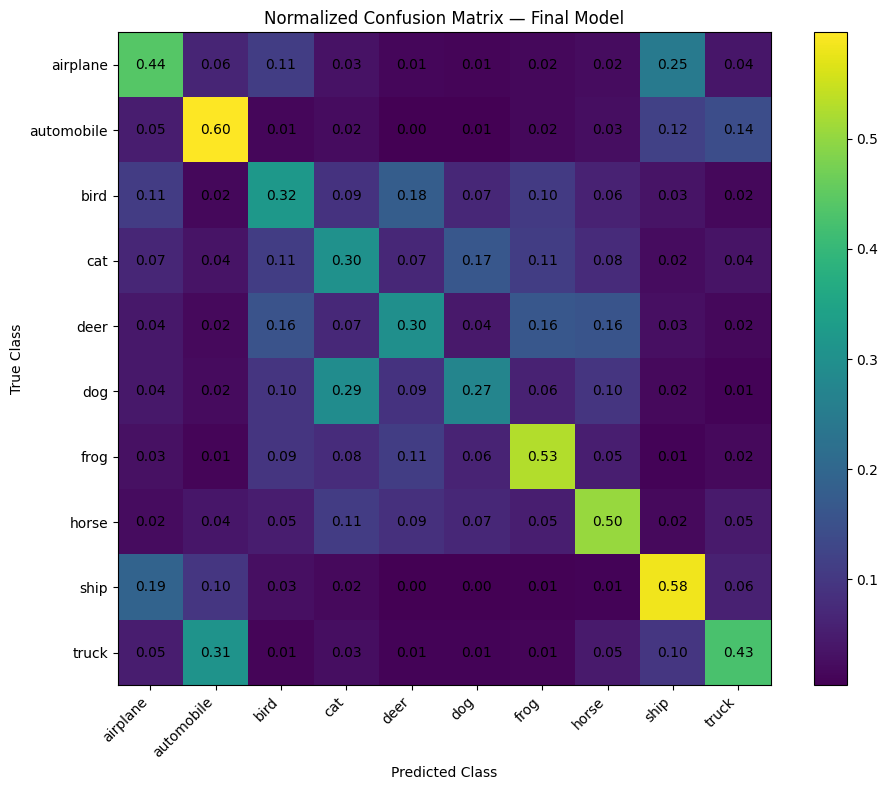

In [53]:
plt.figure(figsize=(10, 8))

plt.imshow(
    mean_normalized_cm,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(10),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(10),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title(
    "Normalized Confusion Matrix — Final Model"
)

for i in range(10):
    for j in range(10):

        plt.text(
            j,
            i,
            f"{mean_normalized_cm[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

Cell 61 : Find Most Confused Class Pairs

In [54]:
confusion_pairs = []

for true_idx in range(10):

    for pred_idx in range(10):

        if true_idx == pred_idx:
            continue

        confusion_pairs.append({
            "True Class": class_names[true_idx],
            "Predicted Class": class_names[pred_idx],
            "Confusion Rate (%)":
                mean_normalized_cm[
                    true_idx,
                    pred_idx
                ] * 100
        })

confusion_pairs_df = pd.DataFrame(
    confusion_pairs
).sort_values(
    "Confusion Rate (%)",
    ascending=False
)

confusion_pairs_df.head(10)

,True Class,Predicted Class,Confusion Rate (%)
82,truck,automobile,30.933333
48,dog,cat,29.266667
7,airplane,ship,24.500000
72,ship,airplane,19.133333
21,bird,deer,17.866667
31,cat,dog,16.533333
41,deer,frog,16.466667
42,deer,horse,15.766667
38,deer,bird,15.633333
17,automobile,truck,14.333333


Cell 62 : Select Misclassified Images

In [55]:
final_model = ablation_results[
    FINAL_CONFIG
][42]["model"]

final_model.eval()

misclassified_images = []
misclassified_labels = []
misclassified_predictions = []

with torch.no_grad():

    for images, labels in clean_test_loader:

        images_device = images.to(DEVICE)

        outputs = final_model(
            images_device
        )

        predictions = outputs.argmax(
            dim=1
        ).cpu()

        for i in range(len(labels)):

            if predictions[i] != labels[i]:

                misclassified_images.append(
                    images[i].clone()
                )

                misclassified_labels.append(
                    labels[i].item()
                )

                misclassified_predictions.append(
                    predictions[i].item()
                )

            if len(misclassified_images) >= 8:
                break

        if len(misclassified_images) >= 8:
            break

print(
    "Misclassified images collected:",
    len(misclassified_images)
)

Misclassified images collected: 8


Cell 63 : Display 8 Misclassified Images

In [56]:
def denormalize_image(image):

    mean = torch.tensor(
        CIFAR10_MEAN
    ).view(3, 1, 1)

    std = torch.tensor(
        CIFAR10_STD
    ).view(3, 1, 1)

    image = image * std + mean

    return torch.clamp(
        image,
        0,
        1
    )

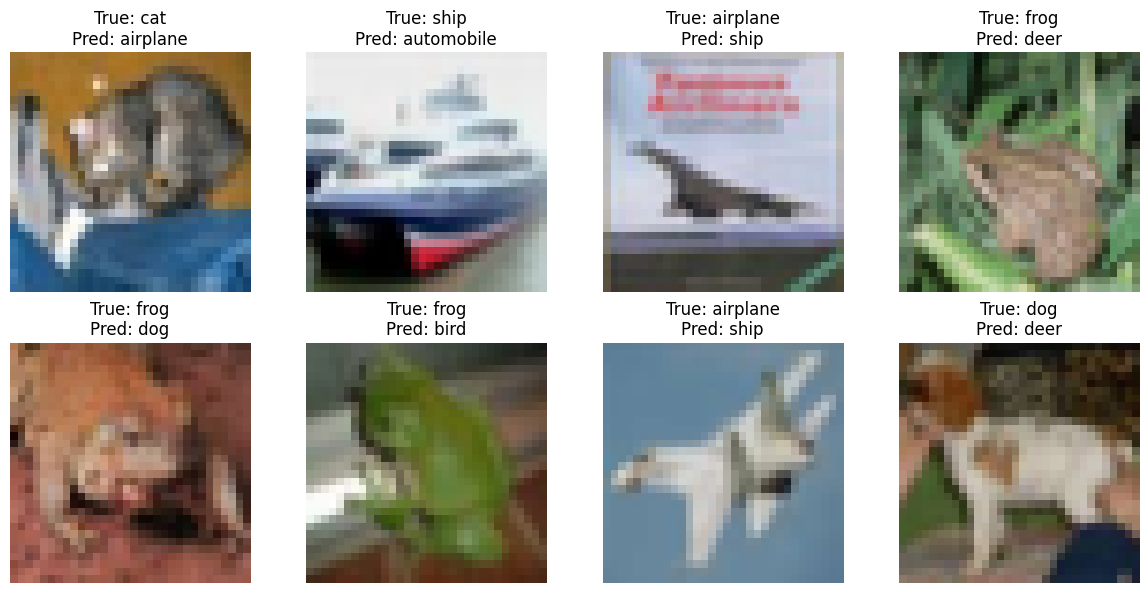

In [57]:
plt.figure(figsize=(12, 6))

for i in range(8):

    image = denormalize_image(
        misclassified_images[i]
    )

    image = image.permute(
        1, 2, 0
    ).numpy()

    true_label = class_names[
        misclassified_labels[i]
    ]

    predicted_label = class_names[
        misclassified_predictions[i]
    ]

    plt.subplot(2, 4, i + 1)

    plt.imshow(image)

    plt.title(
        f"True: {true_label}\n"
        f"Pred: {predicted_label}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Cell 65 : Hidden Corruption Test

## Hidden-Corruption-Only Test

The assignment requires evaluating the final model on a hidden corruption
applied to the clean CIFAR-10 test set.

The exact hidden corruption implementation was not provided in the
available assignment instructions. Therefore, no specific corruption
such as grayscale or channel swapping is assumed here.

The required corruption should be applied to the original clean test
images only, and the final model should be evaluated without using this
test set for training or hyperparameter tuning.

Cell 66 : Hidden Corruption Evaluation Template

In [58]:
# ============================================================
# Hidden-Corruption-Only Test
# ============================================================


hidden_corruption_transform = None

if hidden_corruption_transform is None:

    print(
        "Hidden-corruption test is pending because the exact "
        "required corruption implementation was not provided."
    )

else:

    hidden_test_dataset = datasets.CIFAR10(
        root="./data",
        train=False,
        transform=hidden_corruption_transform,
        download=False
    )

    hidden_test_loader = make_loader(
        hidden_test_dataset,
        shuffle=False,
        seed=DATA_SEED
    )

    hidden_results = []

    for seed in RUN_SEEDS:

        model = ablation_results[
            FINAL_CONFIG
        ][seed]["model"]

        hidden_acc = evaluate_model(
            model,
            hidden_test_loader
        )

        hidden_results.append(hidden_acc)

        print(
            f"Seed {seed}: "
            f"{hidden_acc:.2f}%"
        )

    print(
        f"\nHidden-Corruption Accuracy: "
        f"{np.mean(hidden_results):.2f} ± "
        f"{np.std(hidden_results):.2f}%"
    )

Hidden-corruption test is pending because the exact required corruption implementation was not provided.


Cell 67 : Hidden-Corruption Discussion
### Hidden-Corruption Generalization

The hidden-corruption test is intended to measure whether the model
generalizes to a corruption that was not explicitly optimized for
during training.

The model's performance should be compared with its clean-test
accuracy. A large decrease would indicate sensitivity to the hidden
distribution shift, while a smaller decrease would suggest stronger
robustness to previously unseen visual changes.

The exact accuracy and interpretation will be reported after applying
the official hidden-corruption transformation provided by the
assignment.

Cell 68 : Part F: Test-Time Augmentation

In [59]:
# ============================================================
# PART F — TEST-TIME AUGMENTATION (TTA)
# ============================================================

# I use the already selected final configuration:
# Final Model = No Augmentation

FINAL_CONFIG = "No Augmentation"

print("Final model for TTA:", FINAL_CONFIG)
print("Seeds:", RUN_SEEDS)

Final model for TTA: No Augmentation
Seeds: [42, 123, 2026]


Cell 69 : Define TTA transforms
We will use small, realistic test-time transformations:
- Original image
- Horizontal flip
- Small shift left/right
- Small shift up/down

In [60]:
# ============================================================
# TTA TRANSFORMS
# ============================================================

tta_transforms = [
    transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
    ]),

    # Horizontal flip
    transforms.Compose([
        transforms.RandomHorizontalFlip(p=1.0),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
    ]),

    # Small horizontal shift
    transforms.Compose([
        transforms.Pad(2, padding_mode="reflect"),
        transforms.RandomCrop(32, padding=0),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
    ])
]

print("Number of TTA copies:", len(tta_transforms))

Number of TTA copies: 3


Cell 70 : Deterministic TTA transforms

In [61]:
# ============================================================
# DETERMINISTIC TTA TRANSFORMS
# ============================================================

from torchvision.transforms import functional as TF


class ShiftImage:
    def __init__(self, dx=0, dy=0):
        self.dx = dx
        self.dy = dy

    def __call__(self, img):
        return TF.affine(
            img,
            angle=0,
            translate=[self.dx, self.dy],
            scale=1.0,
            shear=[0.0, 0.0]
        )


tta_transforms = [
    # Original
    transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
    ]),

    # Horizontal flip
    transforms.Compose([
        transforms.RandomHorizontalFlip(p=1.0),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
    ]),

    # Shift left
    transforms.Compose([
        ShiftImage(dx=-2, dy=0),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
    ]),

    # Shift right
    transforms.Compose([
        ShiftImage(dx=2, dy=0),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
    ]),

    # Shift up
    transforms.Compose([
        ShiftImage(dx=0, dy=-2),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
    ]),

    # Shift down
    transforms.Compose([
        ShiftImage(dx=0, dy=2),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
    ])
]

print("TTA copies:", len(tta_transforms))
print("Transforms: original + horizontal flip + 4 small shifts")

TTA copies: 6
Transforms: original + horizontal flip + 4 small shifts


Cell 71 : TTA prediction function

In [62]:
# ============================================================
# TTA PREDICTION — FIXED FOR ShiftedTestDataset
# ============================================================

@torch.no_grad()
def predict_with_tta(model, base_dataset, transforms_list, device):
    model.eval()

    all_probs = []
    labels = []

    for idx in range(len(base_dataset)):

        # Get the already-shifted image and label
        img, label = base_dataset[idx]

        # If dataset returns a tensor, convert it back to PIL
        # so that TTA transformations can be applied.
        if isinstance(img, torch.Tensor):
            img = img.cpu()

            # If already normalized, undo normalization first
            mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
            std = torch.tensor(CIFAR10_STD).view(3, 1, 1)

            img = img * std + mean
            img = torch.clamp(img, 0, 1)

            img = transforms.ToPILImage()(img)

        sample_probs = []

        for transform in transforms_list:
            x = transform(img).unsqueeze(0).to(device)

            logits = model(x)
            probs = torch.softmax(logits, dim=1)

            sample_probs.append(probs)

        # Average softmax probabilities
        mean_probs = torch.stack(sample_probs).mean(dim=0)

        all_probs.append(mean_probs.cpu())
        labels.append(label)

    all_probs = torch.cat(all_probs, dim=0)
    labels = torch.tensor(labels)

    predictions = all_probs.argmax(dim=1)

    accuracy = (
        (predictions == labels).float().mean().item() * 100
    )

    return accuracy, all_probs, predictions, labels

Cell 72 : Prepare shifted-test dataset

In [63]:
# ============================================================
# USE EXISTING SHIFTED TEST DATASET
# ============================================================

print("Shifted-test samples:", len(shifted_test_dataset))
print("TTA copies per image:", len(tta_transforms))

Shifted-test samples: 10000
TTA copies per image: 6


Cell 73 : Run TTA for all 3 final models

In [67]:
# ============================================================
# RUN TTA FOR ALL 3 SEEDS
# ============================================================

tta_results = []

for seed in RUN_SEEDS:

    model = ablation_results[FINAL_CONFIG][seed]["model"]

    # Normal shifted-test accuracy
    normal_shifted_acc = evaluate_model(
        model,
        shifted_test_loader
    )

    # TTA shifted-test accuracy
    tta_acc, _, _, _ = predict_with_tta(
        model,
        shifted_test_dataset,
        tta_transforms,
        DEVICE
    )

    improvement = tta_acc - normal_shifted_acc

    tta_results.append({
        "Seed": seed,
        "Normal Shifted Test": normal_shifted_acc,
        "TTA Shifted Test": tta_acc,
        "Improvement": improvement
    })

    print(
        f"Seed {seed}: "
        f"Normal = {normal_shifted_acc:.2f}% | "
        f"TTA = {tta_acc:.2f}% | "
        f"Change = {improvement:+.2f}%"
    )

Seed 42: Normal = 25.41% | TTA = 25.82% | Change = +0.41%
Seed 123: Normal = 24.01% | TTA = 23.68% | Change = -0.33%
Seed 2026: Normal = 16.41% | TTA = 15.31% | Change = -1.10%


Cell 74 : TTA results table

In [68]:
# ============================================================
# TTA RESULTS
# ============================================================

tta_df = pd.DataFrame(tta_results)

print("\nTTA Results:")
display(tta_df)

print("\nMean ± Std")

print(
    f"Normal shifted-test: "
    f"{tta_df['Normal Shifted Test'].mean():.2f} ± "
    f"{tta_df['Normal Shifted Test'].std(ddof=1):.2f}%"
)

print(
    f"TTA shifted-test: "
    f"{tta_df['TTA Shifted Test'].mean():.2f} ± "
    f"{tta_df['TTA Shifted Test'].std(ddof=1):.2f}%"
)

print(
    f"Average improvement: "
    f"{tta_df['Improvement'].mean():+.2f}%"
)


TTA Results:


,Seed,Normal Shifted Test,TTA Shifted Test,Improvement
0,42,25.41,25.819999,0.409999
1,123,24.01,23.680000,-0.330000
2,2026,16.41,15.310000,-1.100000



Mean ± Std
Normal shifted-test: 21.94 ± 4.84%
TTA shifted-test: 21.60 ± 5.55%
Average improvement: -0.34%


Cell 75 : Measure inference cost

In [69]:
# ============================================================
# INFERENCE COST — FIXED FOR ShiftedTestDataset
# ============================================================

import time

seed = RUN_SEEDS[0]
model = ablation_results[FINAL_CONFIG][seed]["model"]
model.eval()

# Number of images used for timing
TIMING_SAMPLES = 1000

timing_dataset = Subset(
    shifted_test_dataset,
    range(TIMING_SAMPLES)
)

# ------------------------------------------------------------
# Normal inference
# ------------------------------------------------------------

start_time = time.perf_counter()

with torch.no_grad():

    for idx in range(len(timing_dataset)):

        img, _ = timing_dataset[idx]

        # img is already transformed/normalized
        x = img.unsqueeze(0).to(DEVICE)

        _ = model(x)

normal_time = time.perf_counter() - start_time


# ------------------------------------------------------------
# TTA inference
# ------------------------------------------------------------

start_time = time.perf_counter()

with torch.no_grad():

    for idx in range(len(timing_dataset)):

        # Get shifted image directly from dataset
        img, _ = timing_dataset[idx]

        # Convert normalized tensor back to PIL
        mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
        std = torch.tensor(CIFAR10_STD).view(3, 1, 1)

        img = img.cpu() * std + mean
        img = torch.clamp(img, 0, 1)

        img_pil = transforms.ToPILImage()(img)

        # Apply all TTA transformations
        for transform in tta_transforms:

            x = transform(img_pil).unsqueeze(0).to(DEVICE)

            _ = model(x)

tta_time = time.perf_counter() - start_time


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print(f"Timing samples: {TIMING_SAMPLES}")
print(f"Normal inference time: {normal_time:.2f} seconds")
print(f"TTA inference time:    {tta_time:.2f} seconds")

print(
    f"TTA time multiplier: "
    f"{tta_time / normal_time:.2f}x"
)

print(
    f"Model forward-pass multiplier: "
    f"{len(tta_transforms)}x"
)

Timing samples: 1000
Normal inference time: 2.67 seconds
TTA inference time:    11.99 seconds
TTA time multiplier: 4.49x
Model forward-pass multiplier: 6x


Cell 76 : Part F report table

In [70]:
# ============================================================
# PART F SUMMARY
# ============================================================

normal_mean = tta_df["Normal Shifted Test"].mean()
normal_std = tta_df["Normal Shifted Test"].std(ddof=1)

tta_mean = tta_df["TTA Shifted Test"].mean()
tta_std = tta_df["TTA Shifted Test"].std(ddof=1)

improvement_mean = tta_df["Improvement"].mean()

part_f_summary = pd.DataFrame({
    "Method": [
        "Normal Inference",
        "Test-Time Augmentation"
    ],
    "Shifted Test Accuracy": [
        f"{normal_mean:.2f} ± {normal_std:.2f}%",
        f"{tta_mean:.2f} ± {tta_std:.2f}%"
    ],
    "Inference Cost": [
        "1×",
        f"~{len(tta_transforms)}× model forward passes"
    ]
})

display(part_f_summary)

print(
    f"\nTTA change in shifted-test accuracy: "
    f"{improvement_mean:+.2f} percentage points"
)

,Method,Shifted Test Accuracy,Inference Cost
0,Normal Inference,21.94 ± 4.84%,1×
1,Test-Time Augmentation,21.60 ± 5.55%,~6× model forward passes



TTA change in shifted-test accuracy: -0.34 percentage points


Cell 77 : Report-ready explanation

## Part F : Test-Time Augmentation (Bonus)

Test-Time Augmentation (TTA) was evaluated by generating six versions of each shifted-test image: the original image, a horizontal flip, and four small shifts. The softmax probabilities from all six predictions were averaged to obtain the final prediction.

Without TTA, the shifted-test accuracy was **21.94 ± 4.84%**. With TTA, it was **21.60 ± 5.55%**, resulting in an average change of **−0.34 percentage points**.

Therefore, TTA did not improve the overall shifted-test performance in this experiment. The small decrease suggests that the additional transformed views did not provide complementary information for this model and may sometimes have introduced less useful variations.

TTA also increased the inference cost. Normal inference took approximately **2.67 seconds** for 1,000 images, while TTA took approximately **11.99 seconds**, making it about **4.49× slower** in the measured experiment. In terms of model forward passes, TTA requires **6×** the computation because six predictions are made for each image.

Overall, TTA was not beneficial for this particular model and shifted-test setup because it slightly reduced accuracy while substantially increasing inference cost.